In [10]:
import numpy as np
import pandas as pd

from sklearn.metrics import root_mean_squared_error 
from tqdm import tqdm

import matplotlib.pyplot as plt

import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.api import Holt , SimpleExpSmoothing ,ExponentialSmoothing 

In [11]:
electric = pd.read_csv('Electric_Production.csv')
electric

,DATE,IPG2211A2N
0,1985-01-01,72.5052
1,1985-02-01,70.6720
2,1985-03-01,62.4502
3,1985-04-01,57.4714
4,1985-05-01,55.3151
...,...,...
392,2017-09-01,98.6154
393,2017-10-01,93.6137
394,2017-11-01,97.3359
395,2017-12-01,114.7212


In [17]:
y = electric['IPG2211A2N']
y_train , y_test  = y.iloc[:-12] , y.iloc[-12:]

In [21]:
# Simple Exponential
alpha   = np.linspace(0.01,0.99,10)  
scores = []

for a in alpha:
    ses = SimpleExpSmoothing(y_train)
    
    fit1 = ses.fit(smoothing_level=a)
    fcast1 = fit1.forecast(len(y_test))

    
    scores.append([b, root_mean_squared_error(y_test , fcast1)])
    
df_scores = pd.DataFrame(scores, columns = ['alpha'  ,'score'])
df_scores.sort_values('score')

,alpha,score
1,0.99,10.995126
2,0.99,11.216836
3,0.99,11.667430
0,0.99,12.025096
4,0.99,12.329398
5,0.99,13.175071
6,0.99,14.109387
7,0.99,14.982959
8,0.99,15.650099
9,0.99,16.014573


In [26]:
# Exponential Smoothing
alpha , beta  = np.linspace(0.01,0.99,20) , np.linspace(0.01 , 0.99,20) 

scores = []

for a in tqdm(alpha):
    for b in beta: 
        for e in [True,False]:
            holt = Holt(y_train , exponential=e) 
            
            fit1 = holt.fit(smoothing_level=a , smoothing_trend = b, optimized=False)  
            fcast1 = fit1.forecast(len(y_test)) 
               

            scores.append([a,b, e,root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta','exponential','score'])
df_scores.sort_values('score')

100%|██████████| 20/20 [00:07<00:00,  2.84it/s]


,alpha,beta,exponential,score
57,0.061579,0.422632,False,10.078751
56,0.061579,0.422632,True,10.079160
12,0.010000,0.319474,True,10.107375
6,0.010000,0.164737,True,10.127120
32,0.010000,0.835263,True,10.183924
...,...,...,...,...
556,0.680526,0.938421,True,187.442629
516,0.628947,0.938421,True,193.832607
558,0.680526,0.990000,True,198.013266
478,0.577368,0.990000,True,205.617413


In [24]:
alpha , beta , gamma = np.linspace(0.01,0.99,10) , np.linspace(0.01 , 0.99,10) , np.linspace(0.01 , 0.99,10)
season = ['add','mul']
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            for s in season:
             
                hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal=s)   
                
                fit1 = hw_add.fit(smoothing_level=a , smoothing_trend=b, smoothing_seasonal=g)  
                fcast1 = fit1.forecast(len(y_test)) 
                   
    
                scores.append([a,b,g,s, root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta', 'gamma','season','score'])
df_scores.sort_values('score')

100%|██████████| 10/10 [03:54<00:00, 23.43s/it]


,alpha,beta,gamma,season,score
243,0.118889,0.227778,0.118889,mul,4.285620e+00
241,0.118889,0.227778,0.010000,mul,4.315783e+00
988,0.445556,0.990000,0.445556,add,4.345736e+00
242,0.118889,0.227778,0.118889,add,4.395576e+00
245,0.118889,0.227778,0.227778,mul,4.403364e+00
...,...,...,...,...,...
1977,0.990000,0.881111,0.881111,mul,4.153125e+05
1391,0.663333,0.990000,0.554444,mul,6.677404e+05
1996,0.990000,0.990000,0.881111,add,2.469302e+06
1978,0.990000,0.881111,0.990000,add,7.700011e+06


RMSE = 10.03


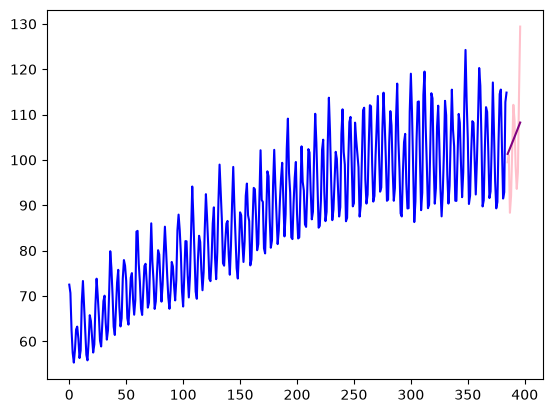

In [29]:
alpha = 0.112

holt = Holt(y_train , exponential='False') 
 
fit1 = holt.fit(smoothing_level=0.06 , smoothing_trend = 0.42, optimized=False)  
fcast1 = fit1.forecast(len(y_test))


y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
print(f'RMSE = {rms}')
